In [14]:
import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [15]:
tf.random.set_seed(42)
np.random.seed(42)

In [16]:
df = pd.read_csv("./DataSet_Encoded_DriveCycles.csv")

In [17]:
pd.DataFrame(df).head()

,w1,w2,w3,wPL,DC,range
0,0.19,0.63,0.94,0.000029,NEDC_extended,168.577083
1,0.43,0.69,0.95,0.000073,FHDS_extended,193.161944
2,0.62,0.12,0.12,0.000062,US06HW_extended,125.559007
3,0.53,0.65,0.41,0.000032,FUDSfast_extended,98.348028
4,0.41,0.44,0.18,0.000074,US06City_extended,134.261982


In [18]:
# Group by DC and find max range for each group
dc_analysis = df.groupby('DC').agg({
    'range': ['max', 'mean', 'count']
}).round(2)

# Reset index to make DC a column
dc_analysis = dc_analysis.reset_index()

# Rename columns for clarity
dc_analysis.columns = ['Drive_Cycle', 'Max_Range', 'Avg_Range', 'Count']

print("\nDrive Cycle Analysis:")
print("====================")
for _, row in dc_analysis.iterrows():
    print(f"\nDrive Cycle: {row['Drive_Cycle']}")
    print(f"Maximum Range: {row['Max_Range']:.2f} km")
    print(f"Average Range: {row['Avg_Range']:.2f} km")
    print(f"Number of samples: {row['Count']}")

# Print the row with the maximum values
max_row = dc_analysis.loc[dc_analysis['Max_Range'].idxmax()]
print("\nDrive Cycle with Maximum Range:")
print("===============================")
print(f"Drive Cycle: {max_row['Drive_Cycle']}")
print(f"Maximum Range: {max_row['Max_Range']:.2f} km")
print(f"Average Range: {max_row['Avg_Range']:.2f} km")
print(f"Number of samples: {max_row['Count']}")


Drive Cycle Analysis:

Drive Cycle: FHDS_extended
Maximum Range: 236.63 km
Average Range: 189.93 km
Number of samples: 100

Drive Cycle: FUDS_extended
Maximum Range: 167.66 km
Average Range: 165.69 km
Number of samples: 102

Drive Cycle: FUDSfast_extended
Maximum Range: 161.04 km
Average Range: 121.58 km
Number of samples: 100

Drive Cycle: NEDC_extended
Maximum Range: 168.58 km
Average Range: 167.83 km
Number of samples: 100

Drive Cycle: US06City_extended
Maximum Range: 190.75 km
Average Range: 147.29 km
Number of samples: 100

Drive Cycle: US06HW_extended
Maximum Range: 184.51 km
Average Range: 145.88 km
Number of samples: 100

Drive Cycle: US06_extended
Maximum Range: 177.56 km
Average Range: 148.47 km
Number of samples: 100

Drive Cycle with Maximum Range:
Drive Cycle: FHDS_extended
Maximum Range: 236.63 km
Average Range: 189.93 km
Number of samples: 100


In [19]:
X = df[['w1', 'w2', 'w3', 'wPL', 'DC']].values
y = df['range'].values

In [20]:
X

array([[0.19, 0.63, 0.94, 2.9e-05, 'NEDC_extended'],
       [0.43, 0.69, 0.95, 7.3e-05, 'FHDS_extended'],
       [0.62, 0.12, 0.12, 6.2e-05, 'US06HW_extended'],
       ...,
       [0.92, 0.35, 0.22, 7.5e-05, 'NEDC_extended'],
       [0.95, 0.54, 0.54, 7.3e-05, 'FHDS_extended'],
       [0.22, 0.13, 0.31, 4.1e-05, 'FUDS_extended']], dtype=object)

In [21]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,NEDC_extended
1,0.43,0.69,0.95,0.000073,FHDS_extended
2,0.62,0.12,0.12,0.000062,US06HW_extended
3,0.53,0.65,0.41,0.000032,FUDSfast_extended
4,0.41,0.44,0.18,0.000074,US06City_extended


In [22]:
# extracting 4th column from X

pd.DataFrame(X[:, 4]).head()




,0
0,NEDC_extended
1,FHDS_extended
2,US06HW_extended
3,FUDSfast_extended
4,US06City_extended


In [23]:
# encoding the 4th column

X[:, 4] = pd.Categorical(X[:, 4]).codes

In [24]:
pd.Series(X[:, 4]).value_counts()

1    102
3    100
0    100
5    100
2    100
4    100
6    100
Name: count, dtype: int64

In [25]:
pd.DataFrame(X).head()

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,3
1,0.43,0.69,0.95,0.000073,0
2,0.62,0.12,0.12,0.000062,5
3,0.53,0.65,0.41,0.000032,2
4,0.41,0.44,0.18,0.000074,4


In [26]:
# comparing the original and encoded values and making a df which contains the original and encoded values for each unique value

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates()

# make a CSV for this DF which is printed

pd.DataFrame({'DC': df['DC'], 'Encoded_DC': X[:, 4]}).drop_duplicates().to_csv('Encoded_DC.csv', index=False)




In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [28]:
# Scale the features
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

In [29]:
# Scale the target variable
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

In [30]:
pd.DataFrame(X_train_scaled).head()

,0,1,2,3,4
0,0.141916,-0.994273,0.302725,0.005905,1.533571
1,-0.429056,0.578500,0.832225,-0.099824,-0.459095
2,1.462290,0.304974,-1.144577,1.450867,0.039072
3,-0.821600,-0.925892,0.726325,0.534550,-0.957261
4,-1.392573,0.749453,-1.215177,1.133681,0.039072


In [31]:
from tensorflow.keras.models import load_model
import numpy as np
import tensorflow as tf

# Define the custom MSE loss function
def mse_function(y_true, y_pred):
    return tf.reduce_mean(tf.square(y_true - y_pred))

# Load the model with the custom MSE function
model = load_model('DNN_Encoded.h5', custom_objects={'mse': mse_function})




In [32]:
# Function to make predictions
def predict_range(w1, w2, w3, wPL, DC):
    # Prepare input data
    input_data = np.array([[w1, w2, w3, wPL, DC]])
    
    # Scale input data
    input_scaled = scaler_X.transform(input_data)
    
    # Make prediction
    prediction_scaled = model.predict(input_scaled)
    
    # Inverse transform the prediction
    prediction = scaler_y.inverse_transform(prediction_scaled.reshape(-1, 1))
    
    return prediction[0][0]


In [33]:
# Evaluate the model
train_predictions = scaler_y.inverse_transform(model.predict(X_train_scaled).reshape(-1, 1))
test_predictions = scaler_y.inverse_transform(model.predict(X_test_scaled).reshape(-1, 1))

train_mse = np.mean((train_predictions.ravel() - y_train) ** 2)
test_mse = np.mean((test_predictions.ravel() - y_test) ** 2)
train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

print(f"Training RMSE: {train_rmse:.2f}")
print(f"Testing RMSE: {test_rmse:.2f}")


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 637us/step
Training RMSE: 8.14
Testing RMSE: 19.00


In [34]:
# Example prediction
example_input = X[0]  # First row of the dataset

pd.DataFrame(example_input).T

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,3


In [35]:
pd.DataFrame(example_input.reshape(1, -1), columns=['w1', 'w2', 'w3', 'wPL', 'DC'])

,w1,w2,w3,wPL,DC
0,0.19,0.63,0.94,0.000029,3


In [36]:
# Example prediction
example_input = X[0]  # First row of the dataset

# Predict without specifying DC explicitly (uses default DC in function)
try:
    predicted_range = predict_range(example_input[0], example_input[1], example_input[2], example_input[3], example_input[4])
    print("\nExample prediction:")
    print(f"Input (w1, w2, w3, wPL): {example_input}")
    print(f"Predicted range: {predicted_range:.2f}")
    print(f"Actual range: {y[0]:.2f}")
except ValueError as e:
    print(f"Error: {e}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

Example prediction:
Input (w1, w2, w3, wPL): [0.19 0.63 0.94 2.9e-05 3]
Predicted range: 168.38
Actual range: 168.58


In [37]:

import matplotlib.pyplot as plt


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 976us/step


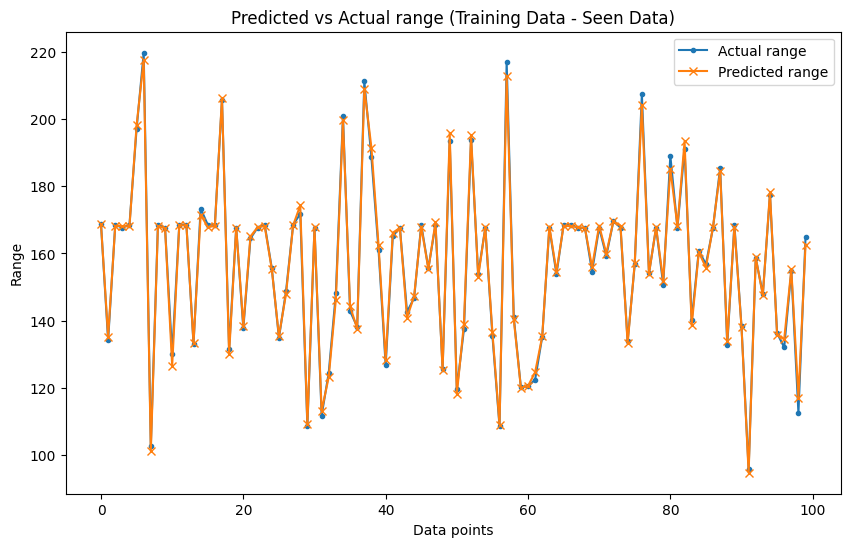

In [38]:
# Predict the range for 100 data points from training set and plot the predictions against the actual values

# Prepare the data

X_train_sample = X_train_scaled[:100]
y_train_sample = y_train[:100]

# Make predictions

train_predictions_sample = scaler_y.inverse_transform(model.predict(X_train_sample).reshape(-1, 1))

# Plot the predictions

plt.figure(figsize=(10, 6))
plt.plot(y_train_sample, label='Actual range', marker='.')
plt.plot(train_predictions_sample, label='Predicted range', marker='x')
plt.xlabel('Data points')
plt.ylabel('Range')
plt.title('Predicted vs Actual range (Training Data - Seen Data)')
plt.legend()
plt.show()


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 804us/step


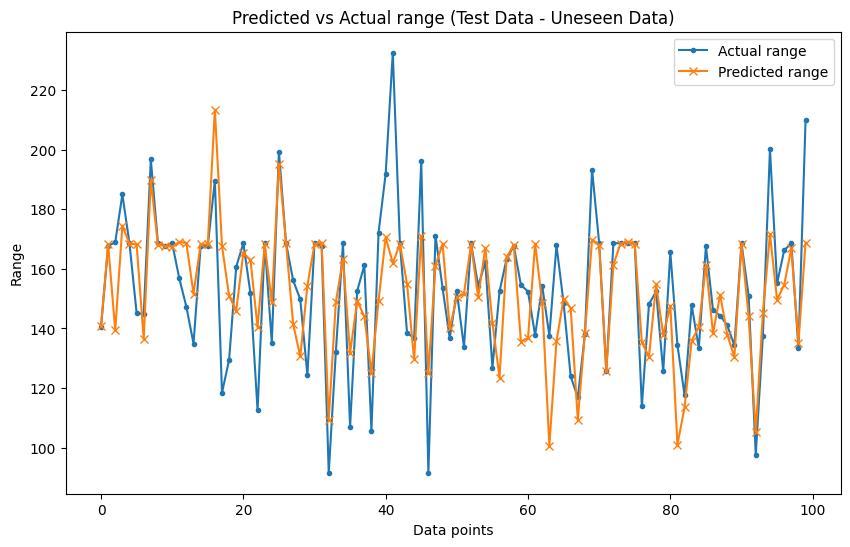

In [39]:
# Predict the range for 100 data points from testing set and plot the predictions against the actual values

# Prepare the data

X_test_sample = X_test_scaled[:100]
y_test_sample = y_test[:100]

# Make predictions

test_predictions_sample = scaler_y.inverse_transform(model.predict(X_test_sample).reshape(-1, 1))

# Plot the predictions

plt.figure(figsize=(10, 6))
plt.plot(y_test_sample, label='Actual range', marker='.')
plt.plot(test_predictions_sample, label='Predicted range', marker='x')
plt.xlabel('Data points')
plt.ylabel('Range')
plt.title('Predicted vs Actual range (Test Data - Uneseen Data)')

plt.legend()
plt.show()



In [40]:
example_input = X[0]  # First row of the dataset

pd.DataFrame(example_input).T

,0,1,2,3,4
0,0.19,0.63,0.94,0.000029,3


In [41]:
# Example prediction
example_input = X[0]  # First row of the dataset

# Predict without specifying DC explicitly (uses default DC in function)
try:
    predicted_range = predict_range(example_input[0], example_input[1], example_input[2], example_input[3], example_input[4])
    print("\nExample prediction:")
    print(f"Input (w1, w2, w3, wPL): {example_input}")
    print(f"Predicted range: {predicted_range:.2f}")
    print(f"Actual range: {y[0]:.2f}")
except ValueError as e:
    print(f"Error: {e}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

Example prediction:
Input (w1, w2, w3, wPL): [0.19 0.63 0.94 2.9e-05 3]
Predicted range: 168.38
Actual range: 168.58


In [ ]:
# ----------------------- FHDS_extende - 0 -----------------------
# Optimal inputs: x1=0.28, x2=0.77, x3=0.20, x4=0.000052
# Predicted range: 232.69

predicted_range = predict_range(0.28, 0.77, 0.20, 0.000052, 0)

print(f"Predicted range: {predicted_range:.2f}")

pd.DataFrame({'w1': [0.28], 'w2': [0.77], 'w3': [0.20], 'wPL': ["0.000052"], 'DC': [0], 'Range': [predicted_range]}).to_csv('Optimised_Bayesian_Values_Range.csv', index=False)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Predicted range: 232.10


In [ ]:
# ----------------------- FUDS_extended - 1 -----------------------
# Optimal inputs: x1=0.97, x2=0.57, x3=0.00, x4=0.000100
# Predicted range: 209.23


predicted_range = predict_range(0.97, 0.57, 0.00, 0.000100, 1)

print(f"Predicted range: {predicted_range:.2f}")

pd.DataFrame({'w1': [0.97], 'w2': [0.57], 'w3': [0.00], 'wPL': ["0.000100"], 'DC': [1], 'Range': [predicted_range]}).to_csv('Optimised_Bayesian_Values_Range.csv', mode='a', header=False, index=False)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Predicted range: 209.23


In [44]:
# ----------------------- FUDSfast_extended - 2 --------------------------------
# x1 = 0.44
# x2 = 0.83
# x3 = 0.73
# x4 = 0.000005
# x5 = 2

# Predicted range: 168.41

predicted_range = predict_range(0.44, 0.83, 0.73, 0.000005, 2)

print(f"Predicted range: {predicted_range:.2f}")

pd.DataFrame({'w1': [0.44], 'w2': [0.83], 'w3': [0.73], 'wPL': ["0.000005"], 'DC': [2], 'Range': [predicted_range]}).to_csv('Optimised_Values_Range.csv', mode='a', header=False, index=False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Predicted range: 168.41


In [45]:
# ----------------------- NEDC_extended - 3 --------------------------------
# x1 = 0.32
# x2 = 0.03
# x3 = 0.84
# x4 = 0.000043
# x5 = 3

# Predicted range: 189.51


predicted_range = predict_range(0.32, 0.03, 0.84, 0.000043, 3)

print(f"Predicted range: {predicted_range:.2f}")

pd.DataFrame({'w1': [0.32], 'w2': [0.03], 'w3': [0.84], 'wPL': ["0.000043"], 'DC': [3], 'Range': [predicted_range]}).to_csv('Optimised_Values_Range.csv', mode='a', header=False, index=False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Predicted range: 189.51


In [46]:
# --------------------- US06City_extended - 4 ------------------------------
# x1 = 0.24
# x2 = 0.00
# x3 = 0.91
# x4 = 0.000060
# x5 = 4

# Predicted range: 193.17


predicted_range = predict_range(0.24, 0.00, 0.91, 0.000060, 4)

print(f"Predicted range: {predicted_range:.2f}")

pd.DataFrame({'w1': [0.24], 'w2': [0.00], 'w3': [0.91], 'wPL': ["0.000060"], 'DC': [4], 'Range': [predicted_range]}).to_csv('Optimised_Values_Range.csv', mode='a', header=False, index=False)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Predicted range: 193.17


In [47]:
# ------------------------- US06HW_extended - 5 ------------------------------
# x1 = 0.00
# x2 = 0.80
# x3 = 0.97
# x4 = 0.000000
# x5 = 5

# Predicted range: 175.63

predicted_range = predict_range(0.00, 0.80, 0.97, 0.000000, 5)

print(f"Predicted range: {predicted_range:.2f}")

pd.DataFrame({'w1': [0.00], 'w2': [0.80], 'w3': [0.97], 'wPL': ["0.000000"], 'DC': [5], 'Range': [predicted_range]}).to_csv('Optimised_Values_Range.csv', mode='a', header=False, index=False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Predicted range: 175.63


In [48]:
# ---------------------- US06_extended - 6 ------------------------------
# x1 = 0.70
# x2 = 1.00
# x3 = 0.62
# x4 = 0.000020

# x5 = 6

# Predicted range: 175.56

predicted_range = predict_range(0.70, 1.00, 0.62, 0.000020, 6)

print(f"Predicted range: {predicted_range:.2f}")

# pd.DataFrame({'w1': [0.70], 'w2': [1.00], 'w3': [0.62], 'wPL': ["0.000020"], 'DC': [6], 'Range': [predicted_range]}).to_csv('Optimised_Values_Range.csv', mode='a', header=False, index=False)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Predicted range: 175.56


In [66]:
from skopt import gp_minimize
from skopt.space import Real
from skopt.utils import use_named_args
from functools import partial  # For partial function application

# Define the search space for x1, x2, x3, and x4
space = [
    Real(0.0, 1.0, name='x1'),  # x1 in [0, 1], rounded to 2 decimal places
    Real(0.0, 1.0, name='x2'),  # x2 in [0, 1], rounded to 2 decimal places
    Real(0.0, 1.0, name='x3'),  # x3 in [0, 1], rounded to 2 decimal places
    Real(0.0, 0.0001, name='x4')  # x4 in [0, 0.0001], with up to 6 decimal places
]

# Define the objective function for minimization
def objective_function(params, x5):
    x1, x2, x3, x4 = params
    # Use the rounded values of x1, x2, x3, and x4
    x1 = round(x1, 2)
    x2 = round(x2, 2)
    x3 = round(x3, 2)
    x4 = round(x4, 8)
    
    # Call the prediction function with the fixed x5 value
    return -predict_range(x1, x2, x3, x4, x5)  # Negative for maximization

# Initialize an empty dictionary to store the optimal results for each x5
optimal_results = {}

# Loop over each value of x5 from 0 to 6
for x5_value in range(7):  # x5 values from 0 to 6
    print(f"Optimizing for x5 = {x5_value}...")

    # Create a version of the objective function with fixed x5
    fixed_x5_function = partial(objective_function, x5=x5_value)
    
    # Run Bayesian Optimization with Expected Improvement
    result = gp_minimize(fixed_x5_function, space, n_calls=300, n_initial_points=20, acq_func='EI', random_state=42)
    
    # Extract the best result
    x1, x2, x3, x4 = result.x
    optimal_range = -result.fun  # Reverse the negative sign for maximization
    
    # Store the optimal results for this value of x5
    optimal_results[x5_value] = {
        "x1": round(x1, 2),
        "x2": round(x2, 2),
        "x3": round(x3, 2),
        "x4": round(x4, 6),
        "optimal_range": round(optimal_range, 2)
    }

# Print the optimal results for each x5 value
for x5_value, results in optimal_results.items():
    print(f"\nFor x5 = {x5_value}:")
    print(f"  Optimal inputs: x1={results['x1']:.2f}, x2={results['x2']:.2f}, x3={results['x3']:.2f}, x4={results['x4']:.6f}")
    print(f"  Maximum predicted range: {results['optimal_range']:.2f}")


Optimizing for x5 = 0...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 

In [ ]:
# For x5 = 0:
#   Optimal inputs: x1=0.28, x2=0.77, x3=0.20, x4=0.000052
#   Maximum predicted range: 232.71

# For x5 = 1:
#   Optimal inputs: x1=0.97, x2=0.57, x3=0.00, x4=0.000100
#   Maximum predicted range: 209.23

# For x5 = 2:
#   Optimal inputs: x1=0.41, x2=0.06, x3=1.00, x4=0.000057
#   Maximum predicted range: 171.51

# For x5 = 3:
#   Optimal inputs: x1=0.33, x2=0.01, x3=0.84, x4=0.000043
#   Maximum predicted range: 189.48

# For x5 = 4:
#   Optimal inputs: x1=0.28, x2=0.00, x3=0.90, x4=0.000058
#   Maximum predicted range: 192.95

# For x5 = 5:
#   Optimal inputs: x1=0.50, x2=0.00, x3=1.00, x4=0.000051
#   Maximum predicted range: 189.64

# For x5 = 6:
#   Optimal inputs: x1=0.89, x2=0.43, x3=0.91, x4=0.000100
#   Maximum predicted range: 178.44

In [ ]:
# saving optimal range and weights to a CSV file

for x5_value, results in optimal_results.items():
    pd.DataFrame({
        'w1': [results['x1']], 
        'w2': [results['x2']], 
        'w3': [results['x3']], 
        'wPL': [f"{results['x4']}"], 
        'DC': [x5_value], 
        'Range': [results['optimal_range']]
    }).to_csv('Optimised_Bayesian_Values_Range.csv', mode='a', header=False, index=False)
